### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("../visualizations", exist_ok=True)
os.makedirs("../data", exist_ok=True)

### Load all five datasets

In [2]:
df_feature_adoption = pd.read_csv("../data/feature_adoption.csv")
df_user_engagement = pd.read_csv("../data/user_engagement.csv")
df_churn_analysis = pd.read_csv("../data/churn_analysis.csv")
df_api_performance = pd.read_csv("../data/api_performance.csv")
df_experiment_analysis = pd.read_csv("../data/experiment_analysis.csv")

datasets = {
    "Feature Adoption": df_feature_adoption,
    "User Engagement": df_user_engagement,
    "Churn Analysis": df_churn_analysis,
    "API Performance": df_api_performance,
    "Experiment Analysis": df_experiment_analysis
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())


Feature Adoption
Shape: (7, 10)
Columns: ['feature_name', 'total_adopting_users', 'total_users', 'total_usage_count', 'adoption_rate_percentage', 'average_usage_per_adopting_user', 'average_usage_per_record', 'first_adoption_date', 'latest_usage_date', 'adoption_rank']

User Engagement
Shape: (9999, 12)
Columns: ['user_id', 'active_days', 'total_events', 'total_sessions', 'total_api_requests', 'successful_api_requests', 'failed_api_requests', 'api_success_rate_percentage', 'first_activity_date', 'last_activity_date', 'activity_lifespan_days', 'engagement_segment']

Churn Analysis
Shape: (3, 12)
Columns: ['plan_type', 'total_subscriptions', 'total_organizations', 'churned_subscriptions', 'non_churned_subscriptions', 'churn_rate_percentage', 'non_churn_rate_percentage', 'total_monthly_subscription_value', 'average_monthly_price', 'first_subscription_date', 'latest_subscription_date', 'churn_risk_rank']

API Performance
Shape: (6, 13)
Columns: ['endpoint', 'total_api_records', 'total_use

### Analyze feature adoption

In [3]:
display(df_feature_adoption)

feature_numeric = df_feature_adoption.select_dtypes(include="number")

if not feature_numeric.empty:
    display(feature_numeric.describe().T)

,feature_name,total_adopting_users,total_users,total_usage_count,adoption_rate_percentage,average_usage_per_adopting_user,average_usage_per_record,first_adoption_date,latest_usage_date,adoption_rank
0,Analytics Dashboard,2945,10000,737665,29.45,250.48,250.48,2024-01-27 00:00:00+00:00,2026-11-12 00:00:00+00:00,1
1,Rate Limiting,2869,10000,705089,28.69,245.76,245.76,2024-01-17 00:00:00+00:00,2026-11-15 00:00:00+00:00,4
2,API Documentation,2873,10000,724121,28.73,252.04,252.04,2024-01-28 00:00:00+00:00,2026-11-15 00:00:00+00:00,3
3,Webhooks,2913,10000,718339,29.13,246.60,246.60,2024-01-23 00:00:00+00:00,2026-11-15 00:00:00+00:00,2
4,API Authentication,2796,10000,678096,27.96,242.52,242.52,2024-01-22 00:00:00+00:00,2026-11-15 00:00:00+00:00,7
5,SDK Integration,2843,10000,721612,28.43,253.82,253.82,2024-01-24 00:00:00+00:00,2026-11-15 00:00:00+00:00,5
6,API Monitoring,2802,10000,700146,28.02,249.87,249.87,2024-01-23 00:00:00+00:00,2026-11-15 00:00:00+00:00,6


,count,mean,std,min,25%,50%,75%,max
total_adopting_users,7.0,2863.000000,54.726593,2796.00,2822.500,2869.00,2893.00,2945.00
total_users,7.0,10000.000000,0.000000,10000.00,10000.000,10000.00,10000.00,10000.00
total_usage_count,7.0,712152.571429,19475.548078,678096.00,702617.500,718339.00,722866.50,737665.00
adoption_rate_percentage,7.0,28.630000,0.547266,27.96,28.225,28.69,28.93,29.45
average_usage_per_adopting_user,7.0,248.727143,3.940138,242.52,246.180,249.87,251.26,253.82
average_usage_per_record,7.0,248.727143,3.940138,242.52,246.180,249.87,251.26,253.82
adoption_rank,7.0,4.000000,2.160247,1.00,2.500,4.00,5.50,7.00


#### Find the feature with the most adopters

In [4]:
adoption_col = next(
    (
        col for col in [
            "total_adopting_users",
            "adopting_users",
            "adopted_users"
        ]
        if col in df_feature_adoption.columns
    ),
    None
)

feature_col = next(
    (
        col for col in ["feature_name", "feature", "feature_id"]
        if col in df_feature_adoption.columns
    ),
    None
)

if adoption_col and feature_col:
    top_feature = df_feature_adoption.loc[
        df_feature_adoption[adoption_col].idxmax()
    ]

    print("Most adopted feature:")
    display(top_feature.to_frame())

Most adopted feature:


,0
feature_name,Analytics Dashboard
total_adopting_users,2945
total_users,10000
total_usage_count,737665
adoption_rate_percentage,29.45
average_usage_per_adopting_user,250.48
average_usage_per_record,250.48
first_adoption_date,2024-01-27 00:00:00+00:00
latest_usage_date,2026-11-12 00:00:00+00:00
adoption_rank,1


### Analyze user engagement

In [5]:
if "engagement_segment" in df_user_engagement.columns:

    engagement_summary = (
        df_user_engagement["engagement_segment"]
        .value_counts()
        .rename_axis("engagement_segment")
        .reset_index(name="user_count")
    )

    engagement_summary["percentage"] = (
        engagement_summary["user_count"]
        / engagement_summary["user_count"].sum()
        * 100
    )

    display(engagement_summary)

    engagement_summary.to_csv(
        "../data/business_engagement_summary.csv",
        index=False
    )

,engagement_segment,user_count,percentage
0,Moderately Engaged,6685,66.856686
1,Low Engagement,2569,25.692569
2,Highly Engaged,705,7.050705
3,Very Low Engagement,40,0.400040


### Analyze churn

In [6]:
display(df_churn_analysis)

churn_numeric = df_churn_analysis.select_dtypes(include="number")

if not churn_numeric.empty:
    display(churn_numeric.describe().T)

,plan_type,total_subscriptions,total_organizations,churned_subscriptions,non_churned_subscriptions,churn_rate_percentage,non_churn_rate_percentage,total_monthly_subscription_value,average_monthly_price,first_subscription_date,latest_subscription_date,churn_risk_rank
0,Pro,580,580,161,419,27.76,72.24,28420.0,49.0,2024-01-16,2026-05-23,3
1,Free,609,609,185,424,30.38,69.62,0.0,0.0,2024-01-16,2026-06-02,2
2,Enterprise,311,311,111,200,35.69,64.31,61889.0,199.0,2024-02-11,2026-05-15,1


,count,mean,std,min,25%,50%,75%,max
total_subscriptions,3.0,500.000000,164.319810,311.00,445.500,580.00,594.500,609.00
total_organizations,3.0,500.000000,164.319810,311.00,445.500,580.00,594.500,609.00
churned_subscriptions,3.0,152.333333,37.753587,111.00,136.000,161.00,173.000,185.00
non_churned_subscriptions,3.0,347.666667,127.907519,200.00,309.500,419.00,421.500,424.00
churn_rate_percentage,3.0,31.276667,4.040326,27.76,29.070,30.38,33.035,35.69
non_churn_rate_percentage,3.0,68.723333,4.040326,64.31,66.965,69.62,70.930,72.24
total_monthly_subscription_value,3.0,30103.000000,30978.806417,0.00,14210.000,28420.00,45154.500,61889.00
average_monthly_price,3.0,82.666667,103.683814,0.00,24.500,49.00,124.000,199.00
churn_risk_rank,3.0,2.000000,1.000000,1.00,1.500,2.00,2.500,3.00


#### Inspect the churn table's columns before interpreting the values:

In [7]:
print("Churn columns:")
print(df_churn_analysis.columns.tolist())

Churn columns:
['plan_type', 'total_subscriptions', 'total_organizations', 'churned_subscriptions', 'non_churned_subscriptions', 'churn_rate_percentage', 'non_churn_rate_percentage', 'total_monthly_subscription_value', 'average_monthly_price', 'first_subscription_date', 'latest_subscription_date', 'churn_risk_rank']


### Analyze API performance

In [8]:
display(df_api_performance)

api_numeric = df_api_performance.select_dtypes(include="number")

if not api_numeric.empty:
    display(api_numeric.describe().T)

,endpoint,total_api_records,total_users,total_requests,successful_requests,failed_requests,error_rate_percentage,success_rate_percentage,average_response_time_ms,maximum_response_time_ms,error_rate_rank,response_time_rank,api_health_status
0,/api/v1/products,8353,5643,4161118,3952082,209036,5.02,94.98,506.25,999.61,1,6,Needs Improvement
1,/api/v1/webhooks,8222,5636,4129971,3923105,206866,5.01,94.99,510.68,999.96,2,3,Needs Improvement
2,/api/v1/auth,8315,5647,4231665,4019824,211841,5.01,94.99,508.95,999.76,2,5,Needs Improvement
3,/api/v1/orders,8383,5628,4249354,4037237,212117,4.99,95.01,510.58,999.94,3,4,Healthy
4,/api/v1/analytics,8298,5604,4211661,4001543,210118,4.99,95.01,513.88,999.97,3,1,Healthy
5,/api/v1/users,8429,5690,4246916,4035640,211276,4.97,95.03,512.20,999.88,4,2,Healthy


,count,mean,std,min,25%,50%,75%,max
total_api_records,6.0,8.333333e+03,72.090684,8222.00,8.302250e+03,8334.00,8375.500,8429.00
total_users,6.0,5.641333e+03,28.296054,5604.00,5.630000e+03,5639.50,5646.000,5690.00
total_requests,6.0,4.205114e+06,49060.212146,4129971.00,4.173754e+06,4221663.00,4243103.250,4249354.00
successful_requests,6.0,3.994905e+06,47128.351091,3923105.00,3.964447e+06,4010683.50,4031686.000,4037237.00
failed_requests,6.0,2.102090e+05,2000.111797,206866.00,2.093065e+05,210697.00,211699.750,212117.00
error_rate_percentage,6.0,4.998333e+00,0.018348,4.97,4.990000e+00,5.00,5.010,5.02
success_rate_percentage,6.0,9.500167e+01,0.018348,94.98,9.499000e+01,95.00,95.010,95.03
average_response_time_ms,6.0,5.104233e+02,2.637534,506.25,5.093575e+02,510.63,511.820,513.88
maximum_response_time_ms,6.0,9.998533e+02,0.142220,999.61,9.997900e+02,999.91,999.955,999.97
error_rate_rank,6.0,2.500000e+00,1.048809,1.00,2.000000e+00,2.50,3.000,4.00


#### Identify the endpoint column

In [9]:
endpoint_col = next(
    (
        col for col in ["endpoint", "api_endpoint"]
        if col in df_api_performance.columns
    ),
    None
)

if endpoint_col:
    print("Endpoint column:", endpoint_col)

    if "average_response_time_ms" in df_api_performance.columns:
        slowest_endpoint = df_api_performance.loc[
            df_api_performance["average_response_time_ms"].idxmax()
        ]
        print("\nSlowest endpoint:")
        display(slowest_endpoint.to_frame())

    if "error_rate_percentage" in df_api_performance.columns:
        highest_error_endpoint = df_api_performance.loc[
            df_api_performance["error_rate_percentage"].idxmax()
        ]
        print("\nEndpoint with highest error rate:")
        display(highest_error_endpoint.to_frame())

Endpoint column: endpoint

Slowest endpoint:


,4
endpoint,/api/v1/analytics
total_api_records,8298
total_users,5604
total_requests,4211661
successful_requests,4001543
failed_requests,210118
error_rate_percentage,4.99
success_rate_percentage,95.01
average_response_time_ms,513.88
maximum_response_time_ms,999.97



Endpoint with highest error rate:


,0
endpoint,/api/v1/products
total_api_records,8353
total_users,5643
total_requests,4161118
successful_requests,3952082
failed_requests,209036
error_rate_percentage,5.02
success_rate_percentage,94.98
average_response_time_ms,506.25
maximum_response_time_ms,999.61


### Analyze experiment results

In [10]:
display(df_experiment_analysis)

print("Experiment analysis columns:")
print(df_experiment_analysis.columns.tolist())

,experiment_id,variant,assigned_users,sdk_integrations,sdk_integration_rate_pct,first_api_requests,first_api_request_rate_pct,feature_adoptions,feature_adoption_rate_pct,retained_users_d7,d7_retention_rate_pct
0,EXP_FEATURE_ONBOARDING_001,Treatment,3003,2253,75.02,2108,70.20,1951,64.97,1728,57.54
1,EXP_FEATURE_ONBOARDING_001,Control,2997,1804,60.19,1694,56.52,1374,45.85,1530,51.05


Experiment analysis columns:
['experiment_id', 'variant', 'assigned_users', 'sdk_integrations', 'sdk_integration_rate_pct', 'first_api_requests', 'first_api_request_rate_pct', 'feature_adoptions', 'feature_adoption_rate_pct', 'retained_users_d7', 'd7_retention_rate_pct']


### Create a feature adoption chart

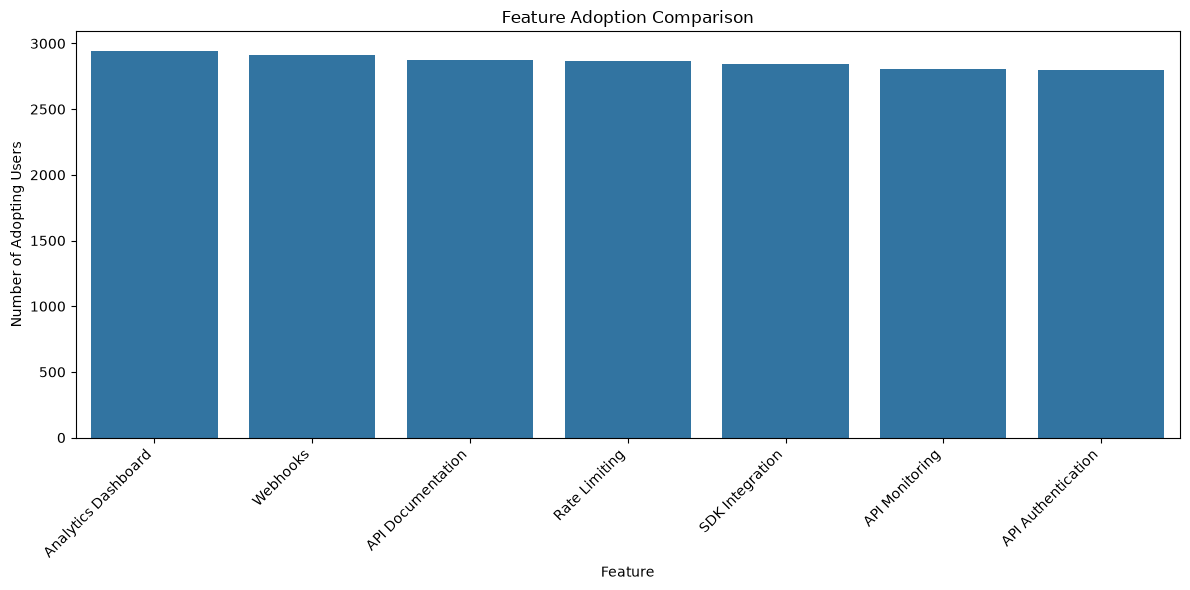

In [11]:
if adoption_col and feature_col:

    plot_df = df_feature_adoption.sort_values(
        adoption_col,
        ascending=False
    )

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=plot_df,
        x=feature_col,
        y=adoption_col
    )

    plt.title("Feature Adoption Comparison")
    plt.xlabel("Feature")
    plt.ylabel("Number of Adopting Users")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        "../visualizations/business_feature_adoption.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

### Create a user engagement chart

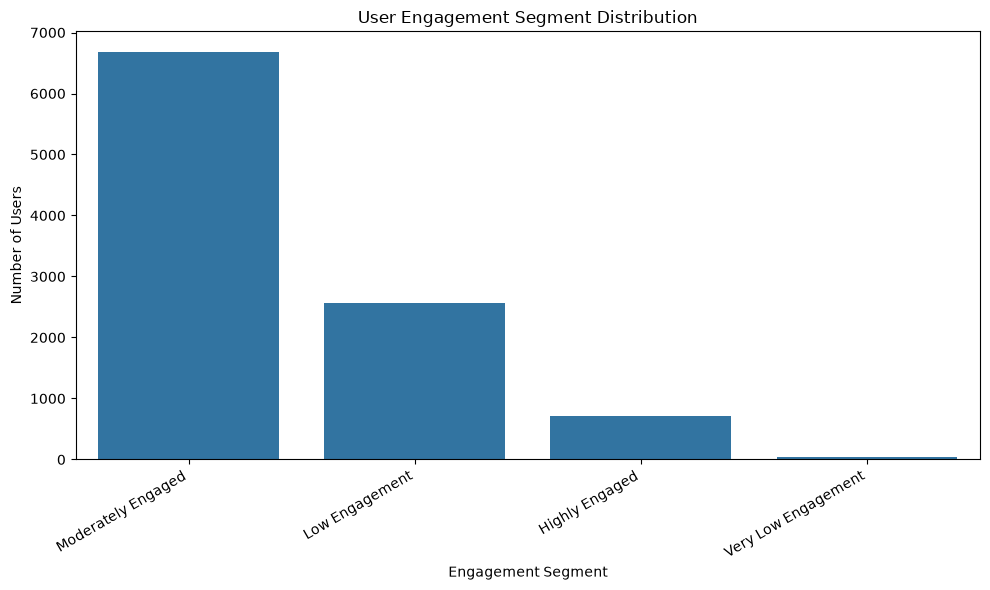

In [12]:
if "engagement_segment" in df_user_engagement.columns:

    plt.figure(figsize=(10, 6))

    sns.countplot(
        data=df_user_engagement,
        x="engagement_segment",
        order=df_user_engagement[
            "engagement_segment"
        ].value_counts().index
    )

    plt.title("User Engagement Segment Distribution")
    plt.xlabel("Engagement Segment")
    plt.ylabel("Number of Users")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    plt.savefig(
        "../visualizations/business_user_engagement.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

### Create an API response time chart

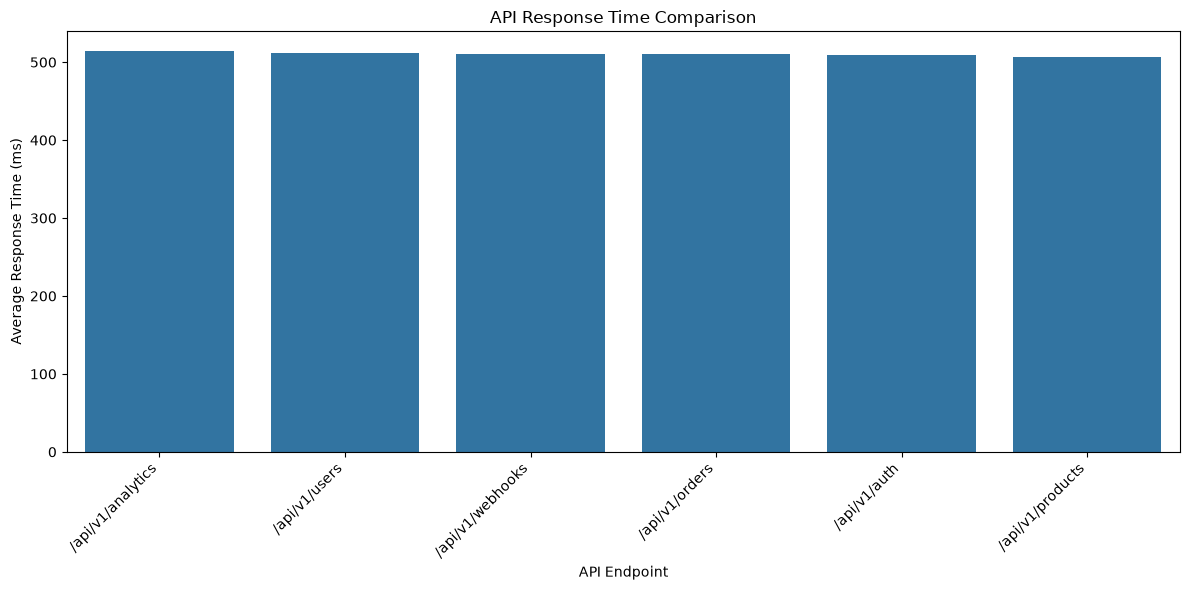

In [13]:
if endpoint_col and "average_response_time_ms" in df_api_performance.columns:

    plot_df = df_api_performance.sort_values(
        "average_response_time_ms",
        ascending=False
    )

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=plot_df,
        x=endpoint_col,
        y="average_response_time_ms"
    )

    plt.title("API Response Time Comparison")
    plt.xlabel("API Endpoint")
    plt.ylabel("Average Response Time (ms)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        "../visualizations/business_api_response_time.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

### Create a business insights report

In [14]:
report_rows = []

for name, df in datasets.items():
    report_rows.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": int(df.isna().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    })

business_report = pd.DataFrame(report_rows)

display(business_report)

business_report.to_csv(
    "../data/business_insights_dataset_summary.csv",
    index=False
)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Feature Adoption,7,10,0,0
1,User Engagement,9999,12,75,0
2,Churn Analysis,3,12,0,0
3,API Performance,6,13,0,0
4,Experiment Analysis,2,11,0,0


### Create a recommendations table

In [15]:
recommendations = pd.DataFrame([
    {
        "Area": "Feature Adoption",
        "Business Question": "Which features have low adoption?",
        "Recommended Action": "Investigate usability and improve feature discovery.",
        "Priority": "High"
    },
    {
        "Area": "User Engagement",
        "Business Question": "Why are some users less engaged?",
        "Recommended Action": "Improve onboarding and provide targeted product guidance.",
        "Priority": "High"
    },
    {
        "Area": "Churn",
        "Business Question": "Which users may be at risk of leaving?",
        "Recommended Action": "Study usage patterns and subscription expiry behavior.",
        "Priority": "High"
    },
    {
        "Area": "API Performance",
        "Business Question": "Which endpoints are slow or unreliable?",
        "Recommended Action": "Investigate slow endpoints and reduce API errors.",
        "Priority": "Medium"
    },
    {
        "Area": "Experimentation",
        "Business Question": "Does a product change improve outcomes?",
        "Recommended Action": "Run user-level A/B tests with appropriate statistical analysis.",
        "Priority": "Medium"
    }
])

display(recommendations)

recommendations.to_csv(
    "../data/business_recommendations.csv",
    index=False
)

,Area,Business Question,Recommended Action,Priority
0,Feature Adoption,Which features have low adoption?,Investigate usability and improve feature disc...,High
1,User Engagement,Why are some users less engaged?,Improve onboarding and provide targeted produc...,High
2,Churn,Which users may be at risk of leaving?,Study usage patterns and subscription expiry b...,High
3,API Performance,Which endpoints are slow or unreliable?,Investigate slow endpoints and reduce API errors.,Medium
4,Experimentation,Does a product change improve outcomes?,Run user-level A/B tests with appropriate stat...,Medium


### Verify saved files

In [16]:
expected_files = [
    "../data/business_engagement_summary.csv",
    "../data/business_insights_dataset_summary.csv",
    "../data/business_recommendations.csv",
    "../visualizations/business_feature_adoption.png",
    "../visualizations/business_user_engagement.png",
    "../visualizations/business_api_response_time.png"
]

for file in expected_files:
    print(
        "Saved:" if os.path.exists(file) else "Not found:",
        file
    )

Saved: ../data/business_engagement_summary.csv
Saved: ../data/business_insights_dataset_summary.csv
Saved: ../data/business_recommendations.csv
Saved: ../visualizations/business_feature_adoption.png
Saved: ../visualizations/business_user_engagement.png
Saved: ../visualizations/business_api_response_time.png


In [17]:
print("Feature Adoption Columns:")
print(df_feature_adoption.columns.tolist())

display(df_feature_adoption)

Feature Adoption Columns:
['feature_name', 'total_adopting_users', 'total_users', 'total_usage_count', 'adoption_rate_percentage', 'average_usage_per_adopting_user', 'average_usage_per_record', 'first_adoption_date', 'latest_usage_date', 'adoption_rank']


,feature_name,total_adopting_users,total_users,total_usage_count,adoption_rate_percentage,average_usage_per_adopting_user,average_usage_per_record,first_adoption_date,latest_usage_date,adoption_rank
0,Analytics Dashboard,2945,10000,737665,29.45,250.48,250.48,2024-01-27 00:00:00+00:00,2026-11-12 00:00:00+00:00,1
1,Rate Limiting,2869,10000,705089,28.69,245.76,245.76,2024-01-17 00:00:00+00:00,2026-11-15 00:00:00+00:00,4
2,API Documentation,2873,10000,724121,28.73,252.04,252.04,2024-01-28 00:00:00+00:00,2026-11-15 00:00:00+00:00,3
3,Webhooks,2913,10000,718339,29.13,246.60,246.60,2024-01-23 00:00:00+00:00,2026-11-15 00:00:00+00:00,2
4,API Authentication,2796,10000,678096,27.96,242.52,242.52,2024-01-22 00:00:00+00:00,2026-11-15 00:00:00+00:00,7
5,SDK Integration,2843,10000,721612,28.43,253.82,253.82,2024-01-24 00:00:00+00:00,2026-11-15 00:00:00+00:00,5
6,API Monitoring,2802,10000,700146,28.02,249.87,249.87,2024-01-23 00:00:00+00:00,2026-11-15 00:00:00+00:00,6


In [18]:
adoption_col = "total_adopting_users"
feature_col = "feature_name"

most_adopted = df_feature_adoption.loc[
    df_feature_adoption[adoption_col].idxmax()
]

print("Most Adopted Feature:")
print("Feature:", most_adopted[feature_col])
print("Adopting Users:", most_adopted[adoption_col])

Most Adopted Feature:
Feature: Analytics Dashboard
Adopting Users: 2945


In [19]:
least_adopted = df_feature_adoption.loc[
    df_feature_adoption[adoption_col].idxmin()
]

print("Least Adopted Feature:")
print("Feature:", least_adopted[feature_col])
print("Adopting Users:", least_adopted[adoption_col])

Least Adopted Feature:
Feature: API Authentication
Adopting Users: 2796


In [20]:
engagement_summary = (
    df_user_engagement["engagement_segment"]
    .value_counts()
)

engagement_percentage = (
    df_user_engagement["engagement_segment"]
    .value_counts(normalize=True) * 100
)

print("Engagement Counts:")
display(engagement_summary)

print("\nEngagement Percentages:")
display(engagement_percentage)

Engagement Counts:


engagement_segment
Moderately Engaged     6685
Low Engagement         2569
Highly Engaged          705
Very Low Engagement      40
Name: count, dtype: int64


Engagement Percentages:


engagement_segment
Moderately Engaged     66.856686
Low Engagement         25.692569
Highly Engaged          7.050705
Very Low Engagement     0.400040
Name: proportion, dtype: float64

In [21]:
print("Churn Analysis Columns:")
print(df_churn_analysis.columns.tolist())

display(df_churn_analysis)

Churn Analysis Columns:
['plan_type', 'total_subscriptions', 'total_organizations', 'churned_subscriptions', 'non_churned_subscriptions', 'churn_rate_percentage', 'non_churn_rate_percentage', 'total_monthly_subscription_value', 'average_monthly_price', 'first_subscription_date', 'latest_subscription_date', 'churn_risk_rank']


,plan_type,total_subscriptions,total_organizations,churned_subscriptions,non_churned_subscriptions,churn_rate_percentage,non_churn_rate_percentage,total_monthly_subscription_value,average_monthly_price,first_subscription_date,latest_subscription_date,churn_risk_rank
0,Pro,580,580,161,419,27.76,72.24,28420.0,49.0,2024-01-16,2026-05-23,3
1,Free,609,609,185,424,30.38,69.62,0.0,0.0,2024-01-16,2026-06-02,2
2,Enterprise,311,311,111,200,35.69,64.31,61889.0,199.0,2024-02-11,2026-05-15,1


In [22]:
display(df_churn_analysis.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
plan_type,3,3,Pro,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_subscriptions,3.0,NaN,NaN,NaN,500.0,164.31981,311.0,445.5,580.0,594.5,609.0
total_organizations,3.0,NaN,NaN,NaN,500.0,164.31981,311.0,445.5,580.0,594.5,609.0
churned_subscriptions,3.0,NaN,NaN,NaN,152.333333,37.753587,111.0,136.0,161.0,173.0,185.0
non_churned_subscriptions,3.0,NaN,NaN,NaN,347.666667,127.907519,200.0,309.5,419.0,421.5,424.0
churn_rate_percentage,3.0,NaN,NaN,NaN,31.276667,4.040326,27.76,29.07,30.38,33.035,35.69
non_churn_rate_percentage,3.0,NaN,NaN,NaN,68.723333,4.040326,64.31,66.965,69.62,70.93,72.24
total_monthly_subscription_value,3.0,NaN,NaN,NaN,30103.0,30978.806417,0.0,14210.0,28420.0,45154.5,61889.0
average_monthly_price,3.0,NaN,NaN,NaN,82.666667,103.683814,0.0,24.5,49.0,124.0,199.0
first_subscription_date,3,2,2024-01-16,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
available_churn = df_churn_analysis.dropna(
    subset=["churned_subscriptions", "non_churned_subscriptions"]
)

total_churned = available_churn["churned_subscriptions"].sum()

total_subscriptions = (
    available_churn["churned_subscriptions"].sum()
    + available_churn["non_churned_subscriptions"].sum()
)

overall_churn_rate = (
    total_churned / total_subscriptions
) * 100

print("Total Churned:", total_churned)
print("Total Subscriptions with Available Churn Data:", total_subscriptions)
print("Overall Churn Rate:", round(overall_churn_rate, 2), "%")

Total Churned: 457
Total Subscriptions with Available Churn Data: 1500
Overall Churn Rate: 30.47 %


In [24]:
print("API Performance Columns:")
print(df_api_performance.columns.tolist())

display(df_api_performance)

API Performance Columns:
['endpoint', 'total_api_records', 'total_users', 'total_requests', 'successful_requests', 'failed_requests', 'error_rate_percentage', 'success_rate_percentage', 'average_response_time_ms', 'maximum_response_time_ms', 'error_rate_rank', 'response_time_rank', 'api_health_status']


,endpoint,total_api_records,total_users,total_requests,successful_requests,failed_requests,error_rate_percentage,success_rate_percentage,average_response_time_ms,maximum_response_time_ms,error_rate_rank,response_time_rank,api_health_status
0,/api/v1/products,8353,5643,4161118,3952082,209036,5.02,94.98,506.25,999.61,1,6,Needs Improvement
1,/api/v1/webhooks,8222,5636,4129971,3923105,206866,5.01,94.99,510.68,999.96,2,3,Needs Improvement
2,/api/v1/auth,8315,5647,4231665,4019824,211841,5.01,94.99,508.95,999.76,2,5,Needs Improvement
3,/api/v1/orders,8383,5628,4249354,4037237,212117,4.99,95.01,510.58,999.94,3,4,Healthy
4,/api/v1/analytics,8298,5604,4211661,4001543,210118,4.99,95.01,513.88,999.97,3,1,Healthy
5,/api/v1/users,8429,5690,4246916,4035640,211276,4.97,95.03,512.20,999.88,4,2,Healthy


In [25]:
slowest_endpoint = df_api_performance.loc[
    df_api_performance["average_response_time_ms"].idxmax()
]

print("Slowest API Endpoint:")
display(slowest_endpoint.to_frame())

Slowest API Endpoint:


,4
endpoint,/api/v1/analytics
total_api_records,8298
total_users,5604
total_requests,4211661
successful_requests,4001543
failed_requests,210118
error_rate_percentage,4.99
success_rate_percentage,95.01
average_response_time_ms,513.88
maximum_response_time_ms,999.97


In [26]:
highest_error_endpoint = df_api_performance.loc[
    df_api_performance["error_rate_percentage"].idxmax()
]

print("Endpoint with Highest Error Rate:")
display(highest_error_endpoint.to_frame())

Endpoint with Highest Error Rate:


,0
endpoint,/api/v1/products
total_api_records,8353
total_users,5643
total_requests,4161118
successful_requests,3952082
failed_requests,209036
error_rate_percentage,5.02
success_rate_percentage,94.98
average_response_time_ms,506.25
maximum_response_time_ms,999.61


In [27]:
if "total_requests" in df_api_performance.columns:

    highest_requests_endpoint = df_api_performance.loc[
        df_api_performance["total_requests"].idxmax()
    ]

    print("Endpoint with Most API Requests:")
    display(highest_requests_endpoint.to_frame())

Endpoint with Most API Requests:


,3
endpoint,/api/v1/orders
total_api_records,8383
total_users,5628
total_requests,4249354
successful_requests,4037237
failed_requests,212117
error_rate_percentage,4.99
success_rate_percentage,95.01
average_response_time_ms,510.58
maximum_response_time_ms,999.94


In [28]:
if "failed_requests" in df_api_performance.columns:

    highest_failed_endpoint = df_api_performance.loc[
        df_api_performance["failed_requests"].idxmax()
    ]

    print("Endpoint with Most Failed Requests:")
    display(highest_failed_endpoint.to_frame())

Endpoint with Most Failed Requests:


,3
endpoint,/api/v1/orders
total_api_records,8383
total_users,5628
total_requests,4249354
successful_requests,4037237
failed_requests,212117
error_rate_percentage,4.99
success_rate_percentage,95.01
average_response_time_ms,510.58
maximum_response_time_ms,999.94


In [29]:
api_ranking = df_api_performance.sort_values(
    by="average_response_time_ms",
    ascending=False
).copy()

display(api_ranking)

api_ranking.to_csv(
    "../data/business_api_performance_ranking.csv",
    index=False
)

,endpoint,total_api_records,total_users,total_requests,successful_requests,failed_requests,error_rate_percentage,success_rate_percentage,average_response_time_ms,maximum_response_time_ms,error_rate_rank,response_time_rank,api_health_status
4,/api/v1/analytics,8298,5604,4211661,4001543,210118,4.99,95.01,513.88,999.97,3,1,Healthy
5,/api/v1/users,8429,5690,4246916,4035640,211276,4.97,95.03,512.20,999.88,4,2,Healthy
1,/api/v1/webhooks,8222,5636,4129971,3923105,206866,5.01,94.99,510.68,999.96,2,3,Needs Improvement
3,/api/v1/orders,8383,5628,4249354,4037237,212117,4.99,95.01,510.58,999.94,3,4,Healthy
2,/api/v1/auth,8315,5647,4231665,4019824,211841,5.01,94.99,508.95,999.76,2,5,Needs Improvement
0,/api/v1/products,8353,5643,4161118,3952082,209036,5.02,94.98,506.25,999.61,1,6,Needs Improvement


In [30]:
print("Experiment Analysis Columns:")
print(df_experiment_analysis.columns.tolist())

display(df_experiment_analysis)

Experiment Analysis Columns:
['experiment_id', 'variant', 'assigned_users', 'sdk_integrations', 'sdk_integration_rate_pct', 'first_api_requests', 'first_api_request_rate_pct', 'feature_adoptions', 'feature_adoption_rate_pct', 'retained_users_d7', 'd7_retention_rate_pct']


,experiment_id,variant,assigned_users,sdk_integrations,sdk_integration_rate_pct,first_api_requests,first_api_request_rate_pct,feature_adoptions,feature_adoption_rate_pct,retained_users_d7,d7_retention_rate_pct
0,EXP_FEATURE_ONBOARDING_001,Treatment,3003,2253,75.02,2108,70.20,1951,64.97,1728,57.54
1,EXP_FEATURE_ONBOARDING_001,Control,2997,1804,60.19,1694,56.52,1374,45.85,1530,51.05


# 6. Overall Business Insights

## 6.1 Executive Summary

This project analyzes DevFlow's product adoption, user engagement, subscription churn, API performance, and feature onboarding experiment. The analysis identifies opportunities to improve product activation, user engagement, subscription retention, API reliability, and the overall developer experience.

## 6.2 Key Business Findings

### 1. Feature Adoption

- Analytics Dashboard is the most adopted feature, with 2,945 adopting users.
- API Authentication is the least adopted feature, with 2,796 adopting users.
- The difference between the highest and lowest adoption is 149 users.
- This indicates an opportunity to improve feature discoverability and onboarding for less-adopted features.

### 2. User Engagement

- Moderately Engaged users represent the largest segment, with 6,685 users (66.86%).
- Low Engagement users account for 25.69%.
- Very Low Engagement users account for 0.40%.
- Combined, approximately 26.09% of users have low or very low engagement.
- Improving onboarding, product education, and feature discovery may help increase engagement.

### 3. Subscription Churn

- The reported overall churn rate is 30.47%, based on 457 churned subscriptions out of 1,500 subscriptions with available churn data.
- The Free plan has a reported churn rate of 30.38%.
- The Pro plan has a reported churn rate of 27.76%.
- The Free plan has a higher reported churn rate than the Pro plan.
- Enterprise churn values are missing in the displayed results.
- Subscription expiry is used as a proxy for churn, not confirmed customer cancellation.

**Data limitation:** The displayed Free and Pro rows total 1,189 subscriptions, while the overall calculation reports 1,500. This discrepancy must be verified before publishing the overall churn result.

### 4. API Performance

- The Analytics endpoint has the slowest average response time at 513.88 ms.
- The Products endpoint has the highest error rate at 5.02%.
- The Orders endpoint handles the highest request volume, with 4,249,354 requests.
- The Orders endpoint also has the highest number of failed requests, with 212,117.
- The Products endpoint has the fastest average response time at 506.25 ms.
- The Users endpoint has the lowest error rate at 4.97%.

These findings indicate that API response time, reliability, and request volume should be monitored separately.

### 5. Experimentation Analysis

- The experiment compared Treatment and Control groups for feature onboarding.
- Treatment achieved a 75.02% SDK integration rate, compared with 60.19% for Control.
- Treatment achieved a 70.20% first API request rate, compared with 56.52% for Control.
- Treatment achieved a 64.97% feature adoption rate, but the Control value is missing.
- Treatment achieved a 57.54% D7 retention rate, but the Control value is missing.

The available results suggest higher early activation rates in the Treatment group. However, missing Control metrics and the aggregate-only data prevent a complete experiment evaluation or a confirmed causal conclusion.

## 6.3 Strategic Business Recommendations

1. **Improve feature adoption:** Investigate why API Authentication has the lowest adoption and improve its onboarding, documentation, and discoverability.

2. **Increase user engagement:** Develop targeted engagement strategies for users in the Low Engagement and Very Low Engagement segments.

3. **Improve subscription retention:** Investigate subscription expiry patterns, especially for the Free plan, and evaluate retention opportunities for eligible users.

4. **Optimize API performance:** Investigate the Analytics endpoint's response time and the Products endpoint's error rate.

5. **Improve Orders API reliability:** Review the high number of failed requests on the Orders endpoint and monitor its performance under high traffic.

6. **Improve onboarding effectiveness:** Further evaluate the Treatment group's higher SDK integration and first API request rates using complete user-level experiment data.

7. **Strengthen product analytics:** Establish regular monitoring of activation, feature adoption, engagement, retention, churn, and API reliability metrics.

## 6.4 Overall Business Conclusion

The analysis identifies several opportunities to improve the DevFlow platform.

The most important opportunities are improving adoption of less-used features, increasing engagement among low-activity users, investigating subscription churn, and strengthening API reliability.

The onboarding experiment also shows promising differences in early activation metrics for the Treatment group. However, further user-level analysis and statistical testing are necessary before making causal claims or deciding to roll out the onboarding change.

Overall, this project demonstrates how product analytics can transform raw product data into actionable business insights and product improvement recommendations.

## 6.5 Project Limitations

- The project uses synthetic data rather than real production user data.
- The churn metric uses subscription expiry as a proxy rather than confirmed cancellation.
- Some Enterprise churn metrics are missing.
- The displayed churn aggregates contain a discrepancy that requires verification.
- The experiment data is aggregated and contains missing Control metrics.
- The available experiment data is insufficient for user-level statistical significance testing or causal inference.

These limitations should be considered when interpreting the findings and presenting the project in a professional portfolio.